# TCL model vs XGBoost

Compares the Mathieu triple-contact-line model with its XGBoost surrogate for a chosen fluid, pressure, integration height $\delta$ and $\Delta T$ range.
- `fluid`: `'FC72'` or any CoolProp name (`'Water'`, `'Nitrogen'`, `'R134a'`, ...)
- `delta`: height at which $q'$ and $\theta_{app}$ are evaluated (the integration stops at $y = \delta$)
- Trained range: P 0.6-154 bar (max 0.7 $P_{crit}$), $\Delta T$ 0.1-40 K, $\delta$ 0.5-50 $\mu$m, $\theta_{mic}$ 5-40 deg, $f$ 0.02-1. The notebook will print a warning if a point is chosen outside this range.

Run from this folder. Requirements in `requirements.txt`.

In [7]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from Mathieu import MathieuModel
import tcl_predictor as tcl

clr_map = [
    "#1f77b4", "#ff7f0e",  "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#7f7f7f",
]

In [8]:
# ── parameters ──
fluid = 'FC72'
P_v = np.array([1,5])*1e5           #Pa
delta = 20e-6                       #m, integration height
DT_v = np.linspace(1,30,5)         #K
theta_mic = 8                       #deg
f = 1                               #accommodation coefficient

In [9]:
# ── Mathieu model ──
rows = []
t0 = time.time()
for P_sat in P_v:
    for DT in DT_v:
        sim = MathieuModel(P_sat, fluid, theta_mic=theta_mic, f=f, maxy=delta)
        sim.DT_def(DT=DT)
        try:
            [s, x, y] = sim.simulate()
            [q_sim, theta_sim] = [y[4][-1], y[2][-1]*180/np.pi]
        except Exception as e:
            print(f"Simulation failed: {str(e)}")
            [q_sim, theta_sim] = [np.nan, np.nan]
        rows.append([P_sat/1e5, DT, q_sim, theta_sim])
print(f"{len(rows)} simulations in {time.time()-t0:.0f} s")

Res = pd.DataFrame(rows, columns=['P [bar]', 'DT [K]', 'q_sim [W/m]', 'theta_sim [deg]'])

10 simulations in 28 s


In [10]:
# ── XGBoost ──
for P_sat in P_v:
    idx = Res['P [bar]'] == P_sat/1e5
    [q_xgb, theta_xgb] = tcl.predict_q_theta(fluid, P_sat, Res.loc[idx,'DT [K]'].values, delta, theta_mic, f)
    Res.loc[idx,'q_xgb [W/m]'] = q_xgb
    Res.loc[idx,'theta_xgb [deg]'] = theta_xgb

Res['err_q [%]'] = (Res['q_xgb [W/m]']/Res['q_sim [W/m]']-1)*100
Res['err_theta [%]'] = (Res['theta_xgb [deg]']/Res['theta_sim [deg]']-1)*100
#Res.to_excel('TCL_model_vs_simulation.xlsx', sheet_name='Data', index=False)

In [11]:
MAPE = Res.groupby('P [bar]')[['err_q [%]', 'err_theta [%]']].apply(lambda e: e.abs().mean())
print("MAPE [%] per pressure")
print(MAPE.round(2))
print(f"Overall MAPE [%]:  q' {Res['err_q [%]'].abs().mean():.2f}   theta_app {Res['err_theta [%]'].abs().mean():.2f}")

MAPE [%] per pressure
         err_q [%]  err_theta [%]
P [bar]                          
1.0           4.95           4.60
5.0           6.55           5.48
Overall MAPE [%]:  q' 5.75   theta_app 5.04


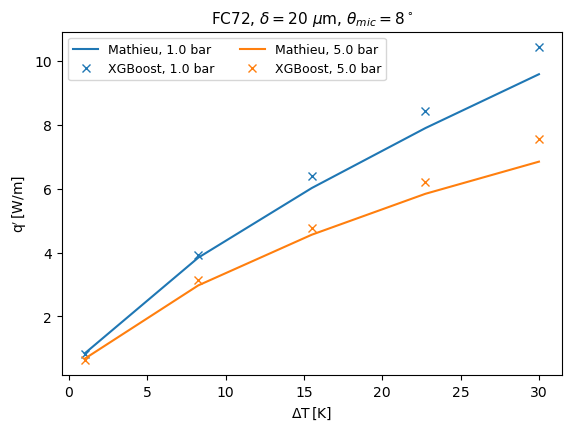

In [12]:
# ── q' vs DT ──
fig, ax = plt.subplots(figsize=(5.6, 4.2), layout='constrained')

for i, P_sat in enumerate(P_v):
    R = Res[Res['P [bar]'] == P_sat/1e5]
    clr = clr_map[i % len(clr_map)]
    ax.plot(R['DT [K]'], R['q_sim [W/m]'], '-', color=clr, label='Mathieu, ' + str(P_sat/1e5) + ' bar')
    ax.plot(R['DT [K]'], R['q_xgb [W/m]'], 'x', color=clr, ms=6, label='XGBoost, ' + str(P_sat/1e5) + ' bar')

ax.set_xlabel(r'$\mathrm{\Delta T \, [K]}$')
ax.set_ylabel(r"$\mathrm{q^{\prime} \, [W/m]}$")
ax.set_title(fluid + r', $\delta = $' + f'{delta*1e6:g}' + r' $\mu$m, $\theta_{mic} = $' + f'{theta_mic:g}' + r'$^\circ$', fontsize=11)
ax.legend(fontsize=9, ncol=2)
#plt.savefig('q_vs_DT.svg', format='svg', bbox_inches="tight")
plt.show()

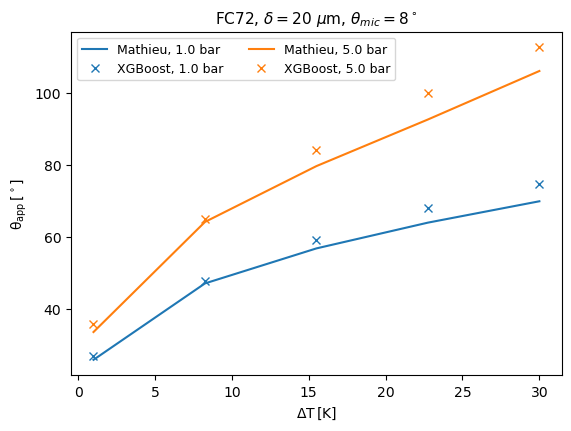

In [13]:
# ── theta_app vs DT ──
fig, ax = plt.subplots(figsize=(5.6, 4.2), layout='constrained')

for i, P_sat in enumerate(P_v):
    R = Res[Res['P [bar]'] == P_sat/1e5]
    clr = clr_map[i % len(clr_map)]
    ax.plot(R['DT [K]'], R['theta_sim [deg]'], '-', color=clr, label='Mathieu, ' + str(P_sat/1e5) + ' bar')
    ax.plot(R['DT [K]'], R['theta_xgb [deg]'], 'x', color=clr, ms=6, label='XGBoost, ' + str(P_sat/1e5) + ' bar')

ax.set_xlabel(r'$\mathrm{\Delta T \, [K]}$')
ax.set_ylabel(r'$\mathrm{\theta_{app} \, [^\circ]}$')
ax.set_title(fluid + r', $\delta = $' + f'{delta*1e6:g}' + r' $\mu$m, $\theta_{mic} = $' + f'{theta_mic:g}' + r'$^\circ$', fontsize=11)
ax.legend(fontsize=9, ncol=2)
#plt.savefig('theta_vs_DT.svg', format='svg', bbox_inches="tight")
plt.show()

In [14]:
# ── results ──
Res.round(3)

,P [bar],DT [K],q_sim [W/m],theta_sim [deg],q_xgb [W/m],theta_xgb [deg],err_q [%],err_theta [%]
0,1.0,1.00,0.836,25.912,0.828,27.096,-0.886,4.570
1,1.0,8.25,3.840,47.113,3.914,47.659,1.942,1.159
2,1.0,15.50,6.024,56.831,6.406,59.173,6.345,4.122
3,1.0,22.75,7.903,63.978,8.440,67.935,6.801,6.184
4,1.0,30.00,9.592,69.909,10.436,74.785,8.800,6.974
5,5.0,1.00,0.670,33.623,0.638,35.782,-4.885,6.422
6,5.0,8.25,2.970,64.173,3.145,64.875,5.878,1.093
7,5.0,15.50,4.560,79.669,4.783,84.248,4.889,5.748
8,5.0,22.75,5.843,92.600,6.226,99.937,6.560,7.923
9,5.0,30.00,6.851,106.057,7.574,112.637,10.548,6.204
